# 04 - Risk Engine

Runs the risk engine in `src/risk/risk_metrics.py` on all companies and saves:

- `data/processed/risk_metrics.csv`
- `data/processed/correlation_matrix.csv`

**Metrics:** daily and annualized volatility, maximum drawdown, Sharpe ratio, Value at Risk (VaR), correlation matrix.

**Beta:** not included yet. It needs a benchmark (e.g. the S&P 500), which is still to be added. See the last section.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Find the project root (the folder that contains "src") so the import works from anywhere
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "risk").exists())
sys.path.insert(0, str(ROOT))

from src.risk import risk_metrics as rm

RAW_FILE = ROOT / "data" / "raw" / "yahoo_prices_raw.csv"
OUT_DIR = ROOT / "data" / "processed"
RISK_FREE_RATE = 0.0   # annual risk-free rate used in the Sharpe ratio (0.03 = 3%)

print("Project root:", ROOT)

Project root: /home/claude


## 2. Load prices

In [2]:
prices = rm.load_prices(RAW_FILE)

print("Shape (days x tickers):", prices.shape)
print("Period:", prices.index.min().date(), "->", prices.index.max().date())
print("Tickers:", list(prices.columns))
prices.head()

Shape (days x tickers): (1254, 10)
Period: 2021-01-04 -> 2025-12-30
Tickers: ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']


ticker,AAPL,AMZN,JNJ,JPM,KO,LLY,MSFT,NVDA,TSLA,XOM
date,,,,,,,,,,
2021-01-04,125.632507,159.331497,133.628342,108.459435,44.527073,156.300873,207.565369,13.046196,243.256668,33.251324
2021-01-05,127.185760,160.925507,135.199387,109.049606,44.037594,157.075317,207.765610,13.335951,245.036667,34.853790
2021-01-06,122.904518,156.919006,136.471619,114.170120,42.636623,155.186478,202.378403,12.549760,251.993332,35.743164
2021-01-07,127.098457,158.108002,136.932739,117.919350,42.164013,156.612518,208.137512,13.275515,272.013336,36.023605
2021-01-08,128.195435,159.134995,136.650970,118.049545,43.109249,157.160263,209.405609,13.208612,293.339996,36.424229


## 3. Calculate the risk metrics

All metrics come from `build_risk_metrics()` in `risk_metrics.py`:

| Metric | Meaning |
|---|---|
| Daily / annualized volatility | Standard deviation of daily returns; annualized by `sqrt(252)` |
| Max drawdown | Worst fall from a previous peak |
| Sharpe ratio | (Annual return - risk-free rate) / annual volatility |
| VaR 95% / 99% | Loss that should not be exceeded on 95% / 99% of days (1-day). Historical = from real returns, parametric = assumes a normal distribution |

In [3]:
metrics, corr, bench_desc = rm.build_risk_metrics(prices, benchmark=None, risk_free_rate=RISK_FREE_RATE)

print("Benchmark:", bench_desc)
metrics.style.format("{:.4f}")

Benchmark: None (beta skipped; pass --benchmark to add it)


,daily_volatility,annualized_volatility,max_drawdown,sharpe_ratio,var_95_hist,var_95_param,var_99_hist,var_99_param
ticker,,,,,,,,
TSLA,0.0383,0.6076,-0.7363,0.5085,0.0585,0.0617,0.0926,0.0878
NVDA,0.0329,0.5224,-0.6634,1.2846,0.0484,0.0515,0.0761,0.0739
AMZN,0.0221,0.3512,-0.5615,0.3918,0.0323,0.0358,0.0561,0.0509
LLY,0.0201,0.3197,-0.3448,1.3726,0.0269,0.0314,0.0454,0.0451
AAPL,0.0176,0.2787,-0.3336,0.6970,0.0281,0.0281,0.0424,0.0401
XOM,0.0170,0.2703,-0.2051,1.0819,0.0266,0.0268,0.0439,0.0385
MSFT,0.0162,0.2572,-0.3715,0.7911,0.0264,0.0258,0.0402,0.0369
JPM,0.0153,0.2428,-0.3877,1.0106,0.0231,0.0242,0.0422,0.0346
JNJ,0.0105,0.1674,-0.1841,0.5899,0.0157,0.0169,0.0262,0.0241


### Same table in percentages (easier to read)

In [4]:
pct = metrics.copy()
for col in ["daily_volatility", "annualized_volatility", "max_drawdown",
            "var_95_hist", "var_95_param", "var_99_hist", "var_99_param"]:
    pct[col] = pct[col] * 100

pct.style.format({
    "daily_volatility": "{:.2f}%", "annualized_volatility": "{:.1f}%", "max_drawdown": "{:.1f}%",
    "sharpe_ratio": "{:.2f}",
    "var_95_hist": "{:.2f}%", "var_95_param": "{:.2f}%", "var_99_hist": "{:.2f}%", "var_99_param": "{:.2f}%",
})

,daily_volatility,annualized_volatility,max_drawdown,sharpe_ratio,var_95_hist,var_95_param,var_99_hist,var_99_param
ticker,,,,,,,,
TSLA,3.83%,60.8%,-73.6%,0.51,5.85%,6.17%,9.26%,8.78%
NVDA,3.29%,52.2%,-66.3%,1.28,4.84%,5.15%,7.61%,7.39%
AMZN,2.21%,35.1%,-56.1%,0.39,3.23%,3.58%,5.61%,5.09%
LLY,2.01%,32.0%,-34.5%,1.37,2.69%,3.14%,4.54%,4.51%
AAPL,1.76%,27.9%,-33.4%,0.70,2.81%,2.81%,4.24%,4.01%
XOM,1.70%,27.0%,-20.5%,1.08,2.66%,2.68%,4.39%,3.85%
MSFT,1.62%,25.7%,-37.1%,0.79,2.64%,2.58%,4.02%,3.69%
JPM,1.53%,24.3%,-38.8%,1.01,2.31%,2.42%,4.22%,3.46%
JNJ,1.05%,16.7%,-18.4%,0.59,1.57%,1.69%,2.62%,2.41%


## 4. Charts

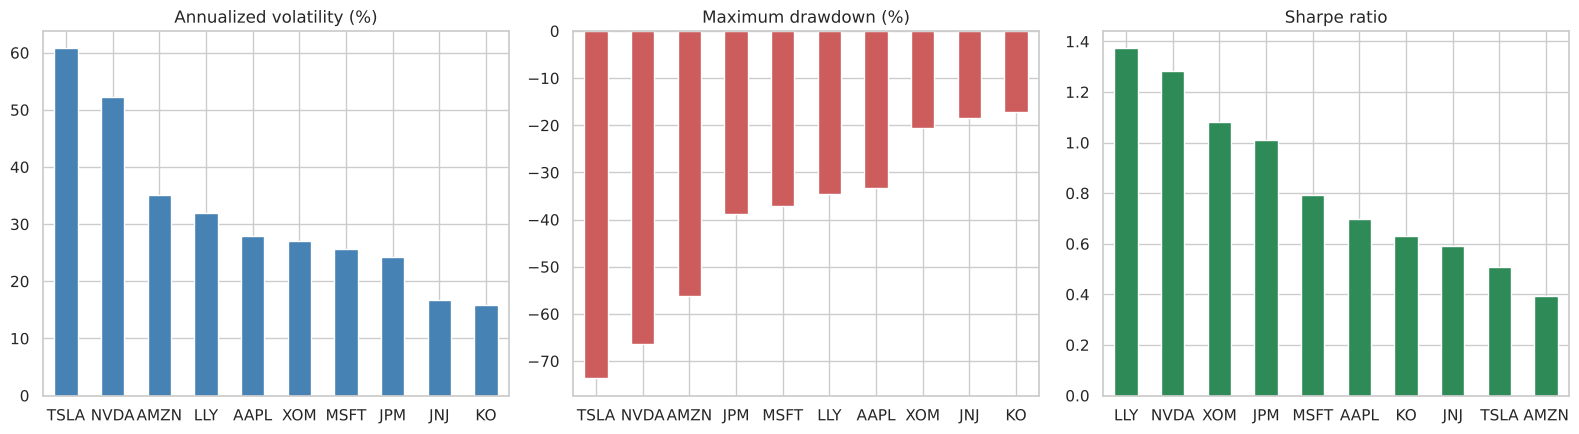

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

(metrics["annualized_volatility"] * 100).sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Annualized volatility (%)")
axes[0].set_xlabel("")

(metrics["max_drawdown"] * 100).sort_values().plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Maximum drawdown (%)")
axes[1].set_xlabel("")

metrics["sharpe_ratio"].sort_values(ascending=False).plot(kind="bar", ax=axes[2], color="seagreen")
axes[2].set_title("Sharpe ratio")
axes[2].set_xlabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

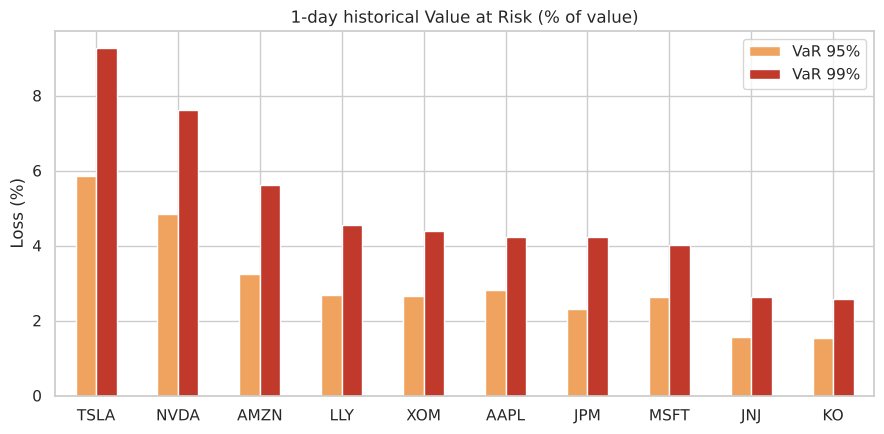

In [6]:
var_plot = (metrics[["var_95_hist", "var_99_hist"]] * 100).sort_values("var_99_hist", ascending=False)
ax = var_plot.plot(kind="bar", figsize=(9, 4.5), color=["#f0a35e", "#c0392b"])
ax.set_title("1-day historical Value at Risk (% of value)")
ax.set_ylabel("Loss (%)")
ax.set_xlabel("")
ax.legend(["VaR 95%", "VaR 99%"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

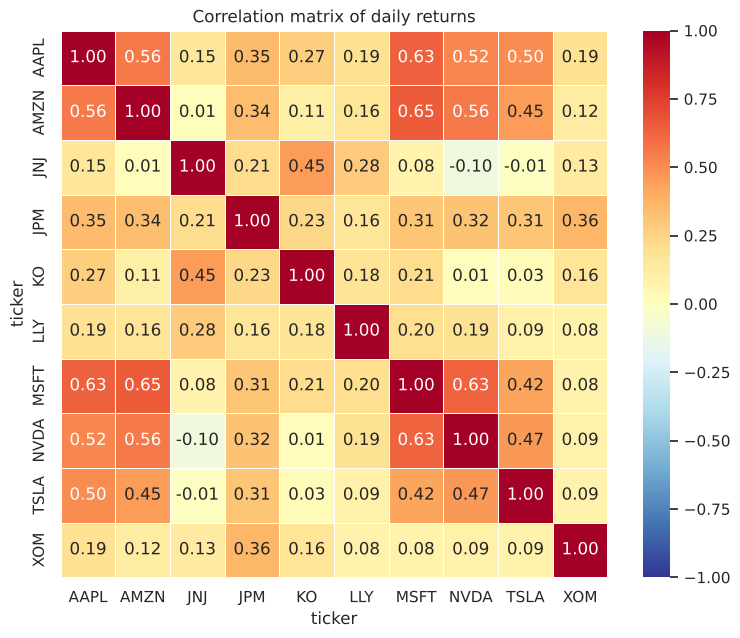

In [7]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix of daily returns")
plt.tight_layout()
plt.show()

## 5. Save the outputs

In [8]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
metrics.to_csv(OUT_DIR / "risk_metrics.csv")
corr.to_csv(OUT_DIR / "correlation_matrix.csv")
print("Saved:", OUT_DIR / "risk_metrics.csv")
print("Saved:", OUT_DIR / "correlation_matrix.csv")

Saved: /home/claude/data/processed/risk_metrics.csv
Saved: /home/claude/data/processed/correlation_matrix.csv


## 6. Quick checks

In [9]:
checks = {
    "10 tickers in output": len(metrics) == prices.shape[1],
    "No missing values": not metrics.isna().any().any(),
    "Correlation matrix is symmetric": bool(np.allclose(corr, corr.T)),
    "Correlation diagonal is 1": bool(np.allclose(np.diag(corr), 1)),
    "Correlations within [-1, 1]": bool(corr.abs().max().max() <= 1 + 1e-9),
    "Max drawdown is negative for every stock": bool((metrics["max_drawdown"] < 0).all()),
    "VaR 99% > VaR 95% for every stock": bool((metrics["var_99_hist"] > metrics["var_95_hist"]).all()),
    "Annualized vol = daily vol x sqrt(252)": bool(np.allclose(
        metrics["annualized_volatility"], metrics["daily_volatility"] * np.sqrt(252))),
}
pd.Series(checks, name="passed").to_frame()

,passed
10 tickers in output,True
No missing values,True
Correlation matrix is symmetric,True
Correlation diagonal is 1,True
"Correlations within [-1, 1]",True
Max drawdown is negative for every stock,True
VaR 99% > VaR 95% for every stock,True
Annualized vol = daily vol x sqrt(252),True


## 7. Key observations

In [10]:
top_vol, low_vol = metrics["annualized_volatility"].idxmax(), metrics["annualized_volatility"].idxmin()
best_sharpe, worst_sharpe = metrics["sharpe_ratio"].idxmax(), metrics["sharpe_ratio"].idxmin()
worst_dd = metrics["max_drawdown"].idxmin()
var_worst = metrics["var_95_hist"].idxmax()

print(f"- Most volatile: {top_vol} ({metrics.loc[top_vol, 'annualized_volatility']:.1%}); least volatile: {low_vol} ({metrics.loc[low_vol, 'annualized_volatility']:.1%}).")
print(f"- Deepest drawdown: {worst_dd} ({metrics.loc[worst_dd, 'max_drawdown']:.1%}).")
print(f"- Best Sharpe: {best_sharpe} ({metrics.loc[best_sharpe, 'sharpe_ratio']:.2f}); worst Sharpe: {worst_sharpe} ({metrics.loc[worst_sharpe, 'sharpe_ratio']:.2f}).")
print(f"- Highest 1-day 95% VaR: {var_worst} ({metrics.loc[var_worst, 'var_95_hist']:.1%} loss on a bad day).")
print(f"- Average pairwise correlation: {corr.values[np.triu_indices_from(corr.values, k=1)].mean():.2f}")

- Most volatile: TSLA (60.8%); least volatile: KO (15.8%).
- Deepest drawdown: TSLA (-73.6%).
- Best Sharpe: LLY (1.37); worst Sharpe: AMZN (0.39).
- Highest 1-day 95% VaR: TSLA (5.8% loss on a bad day).
- Average pairwise correlation: 0.25


## 8. Adding beta later

Beta needs a benchmark such as the S&P 500. When the benchmark file is available:

1. Save it as a CSV with `date` and `close` columns, for example `data/raw/SPY.csv`.
2. In section 3, change `benchmark=None` to `benchmark=str(ROOT / "data" / "raw" / "SPY.csv")`.
3. Re-run all cells. A `beta` column will appear in `risk_metrics.csv`.